# EDA dan Persiapan Data: Deteksi Deforestasi dari Citra Satelit

Notebook Fase 2 proyek Learning Problem Kelompok 10 (deteksi aktivitas deforestasi hutan tropis, SDG 15 target 15.2). Isinya tiga hal: memuat data hasil cleaning, eksplorasi data (EDA) untuk memahami distribusi 17 label, dan membaca hasil split data yang akan dipakai ketiga model.

Urutan menjalankan:

1. Jalankan dulu skrip persiapan dari root proyek: `python scripts/persiapan_data.py`. Skrip itu mengekstrak arsip Kaggle, mengecek integritas citra, menjalankan cleaning, dan membuat split. Hasilnya tertulis di folder `data/processed/`.
2. Jalankan notebook ini dari atas ke bawah. Notebook bisa jalan di Colab maupun lokal, selama folder proyeknya utuh (folder `data` terbaca dari lokasi notebook).

Dataset: Planet, Understanding the Amazon from Space (Kaggle). Setiap citra berukuran 256 x 256 piksel dan bisa membawa beberapa label sekaligus (multi-label), total 17 label.

## 1. Persiapan dan muat data

Sel di bawah ini menyiapkan library, menentukan root proyek, lalu membaca `data/processed/train_v2_clean.csv`. Bila berkas hasil cleaning belum ada, yang dibaca adalah `data/raw/train_v2.csv` apa adanya dan ada keterangan yang dicetak supaya jelas data mana yang sedang dipakai.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Root proyek: folder yang berisi folder data. Notebook ini tinggal di
# notebooks/, jadi root adalah folder induknya. Di Colab sesuaikan bila
# struktur foldernya berbeda.
PROJ = Path.cwd()
if not (PROJ / "data").exists() and (PROJ.parent / "data").exists():
    PROJ = PROJ.parent
RAW = PROJ / "data" / "raw"
PROC = PROJ / "data" / "processed"
FOLDER_CITRA = RAW / "train-jpg"
print("Root proyek:", PROJ)

# Urutan label baku dataset (17 label).
LABELS = [
    "agriculture", "artisinal_mine", "bare_ground", "blooming", "blow_down",
    "clear", "cloudy", "conventional_mine", "cultivation", "habitation",
    "haze", "partly_cloudy", "primary", "road", "selective_logging",
    "slash_burn", "water",
]
CUACA = ["clear", "partly_cloudy", "haze", "cloudy"]
LABEL_LANGKA = [
    "bare_ground", "blooming", "blow_down", "slash_burn",
    "selective_logging", "artisinal_mine", "conventional_mine",
]

path_clean = PROC / "train_v2_clean.csv"
path_raw = RAW / "train_v2.csv"
if path_clean.exists():
    df = pd.read_csv(path_clean, dtype=str)
    sumber = "data/processed/train_v2_clean.csv (hasil cleaning)"
else:
    df = pd.read_csv(path_raw, dtype=str)
    sumber = "data/raw/train_v2.csv (mentah, cleaning belum dijalankan)"
print("Sumber data:", sumber)
print("Jumlah baris:", len(df))
df.head()

Root proyek: /home/hatch/workspace/learning-problem-deforestasi
Sumber data: data/processed/train_v2_clean.csv (hasil cleaning)
Jumlah baris: 40478


,image_name,tags
0,train_0,haze primary
1,train_1,agriculture clear primary water
2,train_2,clear primary
3,train_3,clear primary
4,train_4,agriculture clear habitation primary road


Matriks label biner dibangun dari kolom `tags`: satu baris untuk satu citra, satu kolom untuk satu label, bernilai 1 bila citra membawa label itu. Matriks inilah format yang nanti dipakai semua model.

In [2]:
def bangun_matriks_label(frame: pd.DataFrame) -> pd.DataFrame:
    matriks = pd.DataFrame(0, index=frame["image_name"], columns=LABELS, dtype=int)
    for nama, tags in zip(frame["image_name"], frame["tags"]):
        for lab in str(tags).split():
            if lab in matriks.columns:
                matriks.loc[nama, lab] = 1
    return matriks

Y = bangun_matriks_label(df)
print("Bentuk matriks label:", Y.shape)
Y.iloc[:5, :8]

Bentuk matriks label: (40478, 17)


,agriculture,artisinal_mine,bare_ground,blooming,blow_down,clear,cloudy,conventional_mine
image_name,,,,,,,,
train_0,0,0,0,0,0,0,0,0
train_1,1,0,0,0,0,1,0,0
train_2,0,0,0,0,0,1,0,0
train_3,0,0,0,0,0,1,0,0
train_4,1,0,0,0,0,1,0,0


## 2. Gambaran umum dan distribusi label

Tiga hal dasar yang perlu diketahui sebelum modeling: berapa citra yang ada, seberapa sering tiap label muncul, dan berapa label yang dibawa satu citra. Ketimpangan label adalah isu utama dataset ini, jadi angkanya perlu dilihat dengan jelas sejak awal.

In [3]:
distribusi = pd.DataFrame({
    "jumlah_citra": Y.sum().sort_values(ascending=False),
})
distribusi["persen"] = (distribusi["jumlah_citra"] / len(Y) * 100).round(2)
distribusi

,jumlah_citra,persen
primary,37513,92.68
clear,28431,70.24
agriculture,12315,30.42
road,8071,19.94
water,7410,18.31
partly_cloudy,7261,17.94
cultivation,4477,11.06
habitation,3660,9.04
haze,2697,6.66
cloudy,2089,5.16


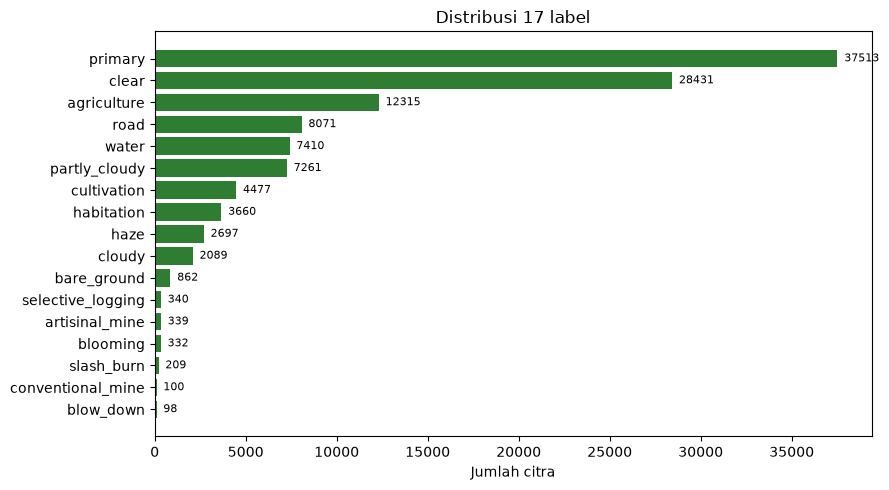

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
urut = Y.sum().sort_values()
ax.barh(urut.index, urut.values, color="#2e7d32")
ax.set_xlabel("Jumlah citra")
ax.set_title("Distribusi 17 label")
for i, v in enumerate(urut.values):
    ax.text(v + max(urut.values) * 0.01, i, str(v), va="center", fontsize=8)
plt.tight_layout()
plt.show()

count    40478.000000
mean         2.870794
std          1.218483
min          1.000000
25%          2.000000
50%          2.000000
75%          4.000000
max          9.000000
dtype: float64


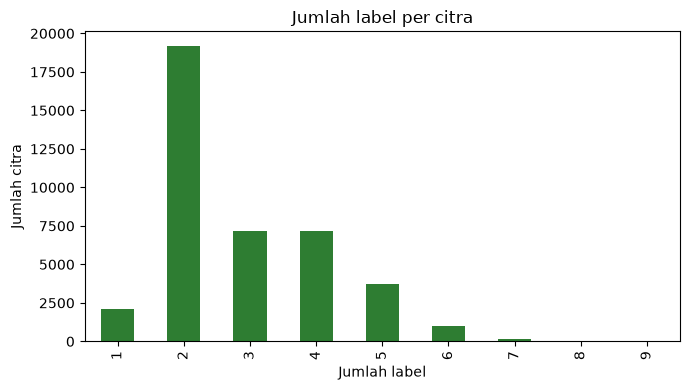

In [5]:
jumlah_label_per_citra = Y.sum(axis=1)
print(jumlah_label_per_citra.describe())
jumlah_label_per_citra.value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4), color="#2e7d32",
    title="Jumlah label per citra", xlabel="Jumlah label", ylabel="Jumlah citra",
)
plt.tight_layout()
plt.show()

### Ko-okurensi label cuaca

Setiap citra seharusnya membawa tepat satu label cuaca dari empat label ini: `clear`, `partly_cloudy`, `haze`, `cloudy`. Matriks di bawah menghitung pasangan label cuaca yang muncul bersamaan dalam satu citra. Pada data hasil cleaning, angka di luar diagonal harus nol karena citra dengan cuaca ambigu sudah dibuang dan citra `cloudy` sudah dipangkas label lainnya. Bila notebook ini dijalankan pada CSV mentah, angka di luar diagonal menunjukkan pelanggaran aturan yang ditangani skrip cleaning.

In [6]:
ko = pd.DataFrame(0, index=CUACA, columns=CUACA, dtype=int)
for a in CUACA:
    for b in CUACA:
        ko.loc[a, b] = int(((Y[a] == 1) & (Y[b] == 1)).sum())
print("Jumlah label cuaca per citra:")
print(Y[CUACA].sum(axis=1).value_counts().sort_index())
ko

Jumlah label cuaca per citra:
1    40478
Name: count, dtype: int64


,clear,partly_cloudy,haze,cloudy
clear,28431,0,0,0
partly_cloudy,0,7261,0,0
haze,0,0,2697,0
cloudy,0,0,0,2089


### Contoh citra per label

Grid di bawah menampilkan contoh citra untuk beberapa label, termasuk tiga label langka yang paling penting untuk proyek ini: `slash_burn`, `selective_logging`, dan `artisinal_mine`. Tujuannya melihat langsung seperti apa tampang tiap label dan seberapa sulit membedakannya dengan mata.

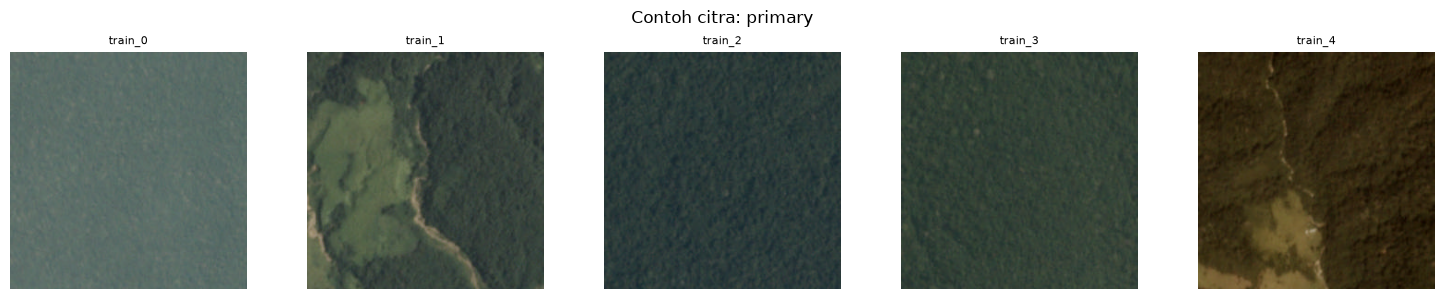

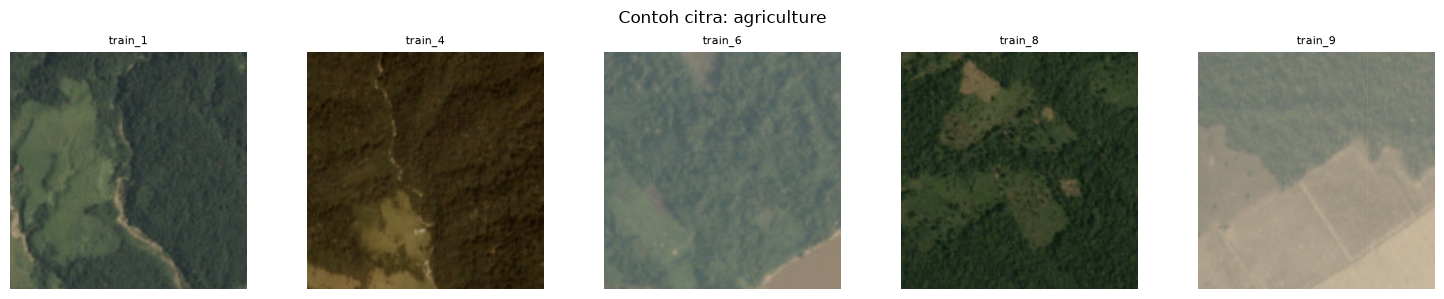

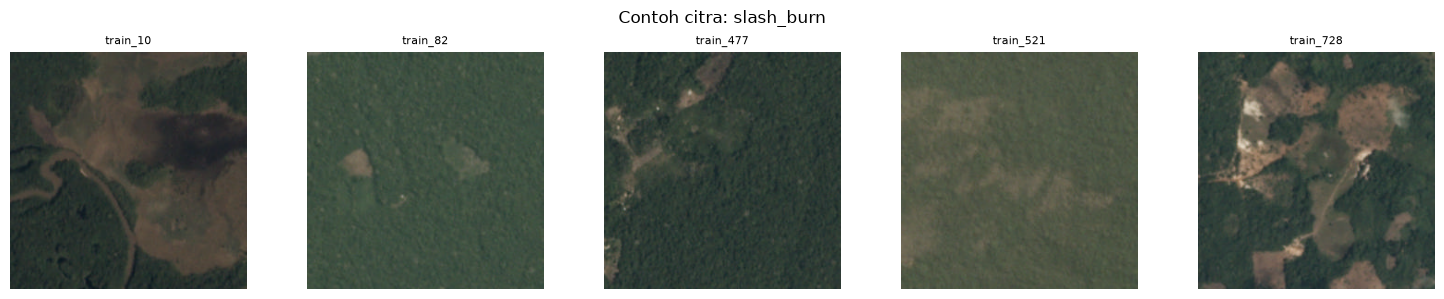

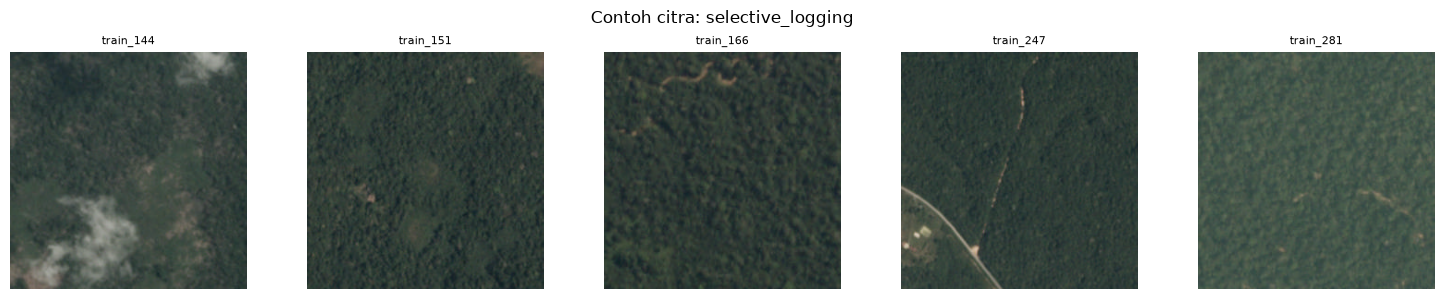

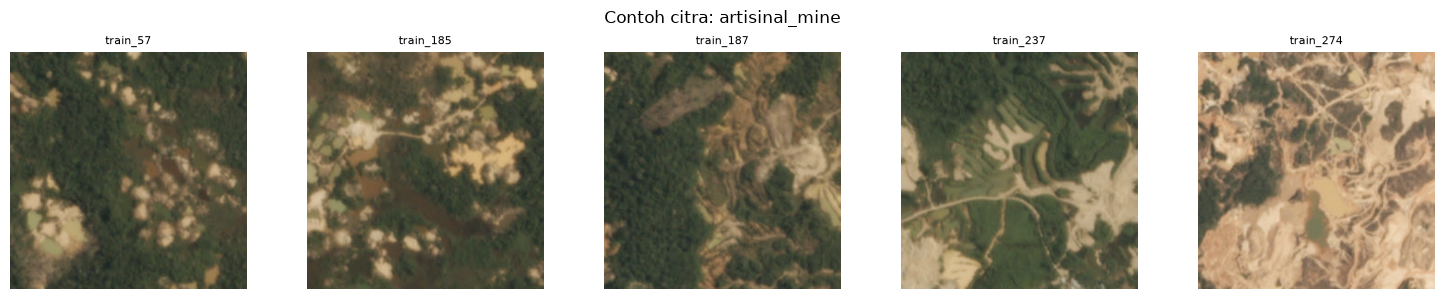

In [7]:
def tampilkan_contoh(label: str, n: int = 5) -> None:
    nama_contoh = Y[Y[label] == 1].index[:n]
    if len(nama_contoh) == 0:
        print(f"Tidak ada citra berlabel {label}")
        return
    fig, axes = plt.subplots(1, len(nama_contoh), figsize=(3 * len(nama_contoh), 3))
    if len(nama_contoh) == 1:
        axes = [axes]
    for ax, nama in zip(axes, nama_contoh):
        path = FOLDER_CITRA / f"{nama}.jpg"
        if path.exists():
            ax.imshow(Image.open(path))
        ax.set_title(nama, fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Contoh citra: {label}")
    plt.tight_layout()
    plt.show()

for label_contoh in ["primary", "agriculture", "slash_burn",
                     "selective_logging", "artisinal_mine"]:
    tampilkan_contoh(label_contoh)

## 3. Ringkasan cleaning

Angka cleaning tidak dihitung ulang di notebook ini, melainkan dibaca dari `data/processed/cleaning_log.json` yang ditulis skrip persiapan, supaya yang dilaporkan di sini selalu sama dengan yang benar benar dilakukan skrip. Kebijakan cleaningnya tetap: citra rusak atau berkasnya hilang dibuang; citra `cloudy` yang membawa label lain dipangkas label non-cuacanya; citra dengan label cuaca ganda atau tanpa label cuaca dibuang dan dicatat; duplikat `image_name` disimpan kemunculan pertamanya.

In [8]:
path_log = PROC / "cleaning_log.json"
if path_log.exists():
    log_clean = json.loads(path_log.read_text(encoding="utf-8"))
    print("Baris CSV awal              :", log_clean["baris_csv_awal"])
    print("Duplikat image_name dibuang :", log_clean["duplikat_image_name"]["jumlah_baris_dibuang"])
    print("File tidak ada di disk      :", log_clean["file_tidak_ada_di_disk"]["jumlah"])
    print("Citra rusak                 :", log_clean["citra_rusak"]["jumlah"])
    print("Baris dibuang (rusak/hilang):", log_clean["baris_dibuang_rusak_atau_hilang"]["jumlah"])
    print("Cloudy, label lain dihapus  :", log_clean["cloudy_label_lain_dihapus"]["jumlah"])
    print("Dibuang, label cuaca ganda  :", log_clean["dibuang_label_cuaca_ganda"]["jumlah"])
    print("Dibuang, tanpa label cuaca  :", log_clean["dibuang_tanpa_label_cuaca"]["jumlah"])
    print("Total data bersih           :", log_clean["total_bersih"])
    print("Metode split                :", log_clean["metode_split"])
else:
    print("cleaning_log.json belum ada. Jalankan dulu scripts/persiapan_data.py.")

Baris CSV awal              : 40479
Duplikat image_name dibuang : 0
File tidak ada di disk      : 0
Citra rusak                 : 0
Baris dibuang (rusak/hilang): 0
Cloudy, label lain dihapus  : 0
Dibuang, label cuaca ganda  : 0
Dibuang, tanpa label cuaca  : 1
Total data bersih           : 40478
Metode split                : fallback lokal: iterative stratification dua tahap plus penyeimbangan tukar (swap) penekan deviasi proporsi label (skmultilearn tidak tersedia)


In [9]:
path_dist = PROC / "label_distribution.csv"
if path_dist.exists():
    dist_cleaning = pd.read_csv(path_dist)
    dist_cleaning
else:
    print("label_distribution.csv belum ada.")

## 4. Split data

Data bersih dibagi menjadi latih 70 persen, validasi 15 persen, dan uji 15 persen dengan iterative stratification (seed 42) supaya proporsi tiap label di tiap split sedekat mungkin dengan proporsi keseluruhan. Tabel di bawah membandingkan proporsi label antar split; selisih yang kecil berarti splitnya sehat dan perbandingan antar model nanti adil.

In [10]:
splits = {}
for nama_split in ["train", "val", "test"]:
    path_split = PROC / f"split_{nama_split}.csv"
    if path_split.exists():
        splits[nama_split] = pd.read_csv(path_split, dtype=str)

if splits:
    print("Ukuran split:", {k: len(v) for k, v in splits.items()})
    tabel_proporsi = pd.DataFrame({"keseluruhan": Y.mean().round(4)})
    for nama_split, frame in splits.items():
        Y_split = bangun_matriks_label(frame)
        tabel_proporsi[nama_split] = Y_split.mean().reindex(LABELS).round(4)
    tabel_proporsi["selisih_maks"] = (
        tabel_proporsi[["train", "val", "test"]].max(axis=1)
        - tabel_proporsi[["train", "val", "test"]].min(axis=1)
    ).round(4)
    tabel_proporsi
else:
    print("Berkas split belum ada. Jalankan dulu scripts/persiapan_data.py.")

Ukuran split: {'train': 28335, 'val': 6071, 'test': 6072}


## 5. Protokol evaluasi yang dikunci

Bagian ini mengunci cara semua model dinilai, supaya hasil baseline, advanced, dan deep learning bisa dibandingkan secara adil dan tidak ada yang mengubah aturan di tengah jalan.

- Tugas: klasifikasi multi-label, 17 label, keluaran berupa skor tiap label untuk tiap citra.
- Metrik utama: F2-score dengan beta = 2 (recall berbobot empat kali precision), dihitung global secara micro di data uji.
- Metrik pendamping: F2 per label dan recall per label, dengan perhatian khusus pada label langka penyebab deforestasi, yaitu `slash_burn`, `selective_logging`, `artisinal_mine`, dan `conventional_mine`.
- Data penilaian: hanya data uji dari split di atas (15 persen, seed 42). Data validasi hanya untuk penalaan, data latih hanya untuk pelatihan. Tidak ada citra yang berpindah split di tengah proyek.
- Threshold model baseline dan advanced: tetap 0,5 untuk semua label, supaya hasil awalnya murni mencerminkan kemampuan model.
- Threshold model deep learning: disetel per label di data validasi (threshold yang memberi F2 per label terbaik di validasi), lalu dipakai apa adanya ke data uji.
- Target proyek: model deep learning mencapai F2 global minimal 0,87 di data uji, dan recall label penyebab deforestasi naik nyata dibandingkan baseline.
- Setiap angka yang dilaporkan harus bisa ditelusur ke notebook modelnya masing masing dan ke split yang sama persis dengan yang dibaca notebook ini.

## 6. Catatan temuan EDA

Setelah notebook ini dijalankan pada data asli, isi bagian ini dengan temuan yang benar benar terlihat dari angka dan gambar di atas, paling tidak:

- Label paling dominan dan label paling langka, beserta angkanya.
- Berapa citra yang dibuang pada cleaning dan alasan terbesarnya.
- Selisih proporsi label terbesar antar split, dan apakah masih wajar.
- Kesan visual dari contoh citra label langka: seberapa mudah dibedakan dari `primary`.

Catatan ini menjadi bahan mentah untuk bab data dan bab metode pada laporan akhir, jadi tulis dengan angka, bukan kesan umum.